First the relevant libraries are imported into the notebook

In [2]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors
from rdkit.Chem import PandasTools

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
sns.set_palette("husl")

from data_profiling import ProfileReport   

Converting the data set SDF file into a CSV using https://stackoverflow.com/questions/78004477/convert-simple-data-format-file-sdf-to-csv

In [21]:
def sdf_to_csv(sdf_file, output_csv_file, delimiter=','):
    """
    Convert an SDF file to a CSV or TSV file.
    
    Args:
        sdf_file (str): Path to the input SDF file.
        output_file (str): Path to the output CSV or TSV file.
        delimiter (str, optional): Delimiter to use in the output file. Default is ',' (CSV).
    """
    # Read the SDF file
    suppl = Chem.SDMolSupplier(sdf_file)

    # Convert to a pandas DataFrame
    df = PandasTools.LoadSDF(sdf_file, smilesName='SMILES', molColName='Molecule', includeFingerprints=False)

    # Drop the 'Molecule' column if present
    if 'Molecule' in df.columns:
        df = df.drop('Molecule', axis=1)

    # Save the DataFrame as CSV or TSV
    df.to_csv(output_csv_file, sep=delimiter, index=False)
    
    print(f"Conversion complete! Output file: {output_csv_file}")

Running the Conversion, and initializing the data set as df for further EDA, saving it as a CSV for easier reference

In [23]:
sdf_file = "data/tox21_10k_data_all.sdf"  # Replace with your SDF file path
output_csv_file = "data/tox21_10k_data_all.csv"  # Output CSV file

sdf_to_csv(sdf_file, output_csv_file, delimiter=',')  # Use ',' for CSV

[10:07:05] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[10:07:05] ERROR: Could not sanitize molecule ending on line 21572
[10:07:05] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[10:07:06] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[10:07:06] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[10:07:06] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[10:07:06] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[10:07:08] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[10:07:08] ERROR: Could not sanitize molecule ending on line 446665
[10:07:08] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[10:07:09] Explicit valence for atom # 1 Cl, 1, is greater than permitted
[10:07:09] ERROR: Could not sanitize molecule ending on l

Conversion complete! Output file: data/tox21_10k_data_all.csv


In [21]:
df = pd.read_csv(output_csv_file)
df

,Formula,FW,DSSTox_CID,SR-HSE,ID,SMILES,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD
0,C27H25ClN6,468.9806 (35.4535+224.2805+209.2465),25848,0.0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,C20H6Br4Na2O5,691.8542 (645.8757+22.9892+22.9892),5234,0.0,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,C47H83NO17,934.1584 (916.1205+18.0379),28909,0.0,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C52H54N4O12,927.0048 (329.4575+89.0275+89.0275+329.4575+90...,5513,1.0,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,C66H87N17O14,1342.5025 (1282.4505+60.0520),26683,NaN,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11756,C7H10N2OS,170.2321,1209,0.0,NCGC00259290-01,CCCc1cc(=O)[nH]c(=S)[nH]1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11757,C3H6N2S,102.1581,601,0.0,NCGC00258846-01,S=C1NCCN1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11758,C3H6N2S,102.1581,601,0.0,NCGC00254936-01,S=C1NCCN1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11759,C10H14NO5PS,291.2606,1100,0.0,NCGC00254571-01,CCOP(=S)(OCC)Oc1ccc([N+](=O)[O-])cc1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


**The above does not need to be run again, aside from importing relevant libraries**

**Loading local versions**

In [3]:
df = pd.read_csv("data/tox21_10k_data_all.csv")
df

,Formula,FW,DSSTox_CID,SR-HSE,ID,SMILES,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD
0,C27H25ClN6,468.9806 (35.4535+224.2805+209.2465),25848,0.0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,C20H6Br4Na2O5,691.8542 (645.8757+22.9892+22.9892),5234,0.0,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,C47H83NO17,934.1584 (916.1205+18.0379),28909,0.0,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C52H54N4O12,927.0048 (329.4575+89.0275+89.0275+329.4575+90...,5513,1.0,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,C66H87N17O14,1342.5025 (1282.4505+60.0520),26683,NaN,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11756,C7H10N2OS,170.2321,1209,0.0,NCGC00259290-01,CCCc1cc(=O)[nH]c(=S)[nH]1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11757,C3H6N2S,102.1581,601,0.0,NCGC00258846-01,S=C1NCCN1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11758,C3H6N2S,102.1581,601,0.0,NCGC00254936-01,S=C1NCCN1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11759,C10H14NO5PS,291.2606,1100,0.0,NCGC00254571-01,CCOP(=S)(OCC)Oc1ccc([N+](=O)[O-])cc1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


Verifying the data set was successfully loaded

Next a sub data set is taken from the overall data set focusing on key characteristics for this project, including the formula, formula weight, ID, smiles, mol object, and the 5 stress response indicators.

In [4]:
df_of_study = df[['ID','SMILES', "Formula", 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53']]
df_of_study.head()

,ID,SMILES,Formula,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,C27H25ClN6,NaN,NaN,0.0,NaN,NaN
1,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,C20H6Br4Na2O5,NaN,NaN,0.0,NaN,NaN
2,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,C47H83NO17,NaN,NaN,0.0,NaN,NaN
3,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,C52H54N4O12,NaN,NaN,1.0,NaN,NaN
4,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,C66H87N17O14,NaN,NaN,NaN,NaN,NaN


The dataset is checked for duplicate molecules

In [5]:
unique_molecules = df_of_study['ID'].nunique()
num_molecules = df_of_study['ID'].shape[0]
print(f'Unique molecules: {unique_molecules}')
print(f'Total molecules: {num_molecules}')

Unique molecules: 11761
Total molecules: 11761


No repeating molecule IDs were found. Next we ensure each smiles value is unique

In [6]:
unique_smiles = df_of_study['SMILES'].nunique()
num_smiles = df_of_study['SMILES'].shape[0]
print(f'Unique SMILES: {unique_smiles}')
print(f'Total SMILES: {num_smiles}')

Unique SMILES: 8041
Total SMILES: 11761


The functions below are declared for adding the mol objects  and cononicalizing isomeric SMILES

In [7]:
def add_mol_object(smile, isomeric:bool=True):
    mol = Chem.MolFromSmiles(smile)
    return mol

def canonicalize_smiles(smiles, isomeric=True):
    if not isinstance(smiles, str) or not smiles.strip():
        return None

    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    return Chem.MolToSmiles(mol, isomericSmiles=isomeric)



df_of_study['mol'] = df_of_study['SMILES'].apply(add_mol_object)
df_of_study['canon_smiles'] = df_of_study['SMILES'].apply(canonicalize_smiles)

[10:20:13] WARNING: not removing hydrogen atom without neighbors
C:\Users\brand\AppData\Local\Temp\ipykernel_21976\732216087.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_of_study['mol'] = df_of_study['SMILES'].apply(add_mol_object)
[10:20:16] WARNING: not removing hydrogen atom without neighbors
C:\Users\brand\AppData\Local\Temp\ipykernel_21976\732216087.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_of_study['canon_smiles'] = df_of_study['SMILES'].apply(canonicalize_smiles)


The mol objects and canon smile format of molecules are added to the dataframe in new columns

Seeing what has changed

In [8]:
changed = df_of_study[df_of_study['SMILES'] != df_of_study['canon_smiles']]

print(f"Total changed: {len(changed)}")


Total changed: 0


The function successfully canonicalized the smiles of some molecules

A function is defined to apply ALL key molecular descriptors to the dataset, it is then run to find and assign these values to the respective molecules.

In [9]:
def calculate_desc(mol):
    description = Descriptors.CalcMolDescriptors(mol, missingVal=None, silent=True)
    return description


descriptors_data = []
for row, smiles in df_of_study['canon_smiles'].items():
    mol = Chem.MolFromSmiles(str(smiles))
    desc = calculate_desc(mol)
    descriptors_data.append(desc)

descriptors_df = pd.DataFrame(descriptors_data)

df_with_descriptors = pd.concat([df_of_study, descriptors_df], axis=1)

df_with_descriptors.head()


[10:22:02] WARNING: not removing hydrogen atom without neighbors
[10:22:02] WARNING: not removing hydrogen atom without neighbors


,ID,SMILES,Formula,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol,canon_smiles,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,C27H25ClN6,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,...,0,0,0,0,0,0,0,0,0,0
1,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,C20H6Br4Na2O5,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,...,0,0,0,0,0,0,0,0,0,0
2,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,C47H83NO17,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,...,0,0,0,0,0,0,0,0,0,0
3,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,C52H54N4O12,NaN,NaN,1.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,...,0,0,0,0,0,0,0,0,0,0
4,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,C66H87N17O14,NaN,NaN,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,...,0,0,0,0,0,0,0,0,0,0


This was the original version used to test the process using a choice of 6 molecular descriptors

def calculate_key_descriptors(mol):
    descriptors = {
        'MolWt': Descriptors.MolWt(mol),
        'LogP' : Descriptors.MolLogP(mol),
        'TPSA': Descriptors.TPSA(mol),
        'NumHDonors': Descriptors.NumHDonors(mol),
        'NumHAcceptors': Descriptors.NumHAcceptors(mol),
        'RotBonds' : Descriptors.NumRotatableBonds(mol)
    }
    return descriptors

descriptor_data = []
for row, mol in df['molecule'].items():
    if mol is None:
        desc = {
            'MolWt': np.nan,
            'LogP': np.nan,
            'TPSA': np.nan,
            'NumHDonors': np.nan,
            'NumHAcceptors': np.nan,
            'RotBonds': np.nan
        }
    else:
        desc = calculate_key_descriptors(mol)
    descriptor_data.append(desc)

descriptor_df = pd.DataFrame(descriptor_data, index=df.index)

df_with_descriptors = pd.concat([df, descriptor_df], axis=1)

df_with_descriptors.head()

Information about the dataset with descriptors is checked

In [10]:
df_with_descriptors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11761 entries, 0 to 11760
Columns: 227 entries, ID to fr_urea
dtypes: float64(112), int64(110), object(5)
memory usage: 20.4+ MB


In [11]:
df_with_descriptors.describe()

c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in su

,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
count,7166.000000,9089.000000,8148.000000,7319.000000,8632.000000,11761.000000,11761.000000,11761.000000,11761.000000,11761.000000,...,11761.000000,11761.000000,11761.000000,11761.000000,11761.000000,11761.00000,11761.000000,11761.000000,11761.000000,11761.000000
mean,0.153084,0.037188,0.052528,0.156032,0.062210,9.950465,9.949023,0.272540,-0.933141,0.544592,...,0.039197,0.040983,0.007907,0.006717,0.003911,0.01505,0.001616,0.011309,0.556585,0.029929
std,0.360094,0.189232,0.223103,0.362911,0.241551,3.062265,3.062113,0.419457,1.610199,0.194535,...,0.223403,0.224791,0.093252,0.081686,0.063768,0.13117,0.044195,0.115726,2.180514,0.185683
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-10.842593,0.008701,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,8.798339,8.798339,0.028221,-1.263794,0.418905,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,10.705926,10.705447,0.132365,-0.476004,0.551848,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,12.084518,12.084518,0.342865,0.000000,0.691354,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,17.442653,17.442653,8.764932,2.120000,0.944994,...,4.000000,2.000000,2.000000,1.000000,2.000000,4.00000,2.000000,3.000000,36.000000,4.000000


Next the correlations between the key descriptors are evaluated by creating a list of all descriptor column names, and using that to test the correlation within the data frame

In [12]:
descriptor_columns = df_with_descriptors.columns[10:]
correlation_matrix = df_with_descriptors[descriptor_columns].corr().abs()

correlation_matrix

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
MaxAbsEStateIndex,1.000000,0.999938,0.393455,0.443970,0.009930,0.241152,0.426671,0.429496,0.427236,0.459927,...,0.038218,0.127737,0.059345,0.018329,0.030493,0.009158,0.018922,0.005324,0.080605,0.095804
MaxEStateIndex,0.999938,1.000000,0.394331,0.441142,0.009303,0.241130,0.426585,0.429416,0.427149,0.459817,...,0.038303,0.127829,0.059388,0.018368,0.030523,0.009105,0.018906,0.005370,0.081406,0.095885
MinAbsEStateIndex,0.393455,0.394331,1.000000,0.036482,0.060168,0.100168,0.215035,0.211231,0.214966,0.228088,...,0.023502,0.054087,0.029402,0.024876,0.022269,0.002294,0.014337,0.000940,0.033264,0.016624
MinEStateIndex,0.443970,0.441142,0.036482,1.000000,0.175782,0.088120,0.363280,0.376838,0.363503,0.332431,...,0.001390,0.361801,0.138614,0.005884,0.001303,0.009112,0.027505,0.005516,0.019590,0.070562
qed,0.009930,0.009303,0.060168,0.175782,1.000000,0.025451,0.348137,0.342790,0.348422,0.339579,...,0.072038,0.109226,0.040326,0.025113,0.046993,0.020843,0.036710,0.037709,0.291681,0.016882
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fr_thiazole,0.009158,0.009105,0.002294,0.009112,0.020843,0.026377,0.074752,0.079163,0.074785,0.061587,...,0.133664,0.025223,0.009730,0.009436,0.064125,1.000000,0.010474,0.005593,0.028694,0.009435
fr_thiocyan,0.018922,0.018906,0.014337,0.027505,0.036710,0.026930,0.027753,0.026810,0.027734,0.031429,...,0.157225,0.006665,0.003100,0.003006,0.002242,0.010474,1.000000,0.003572,0.000375,0.005893
fr_thiophene,0.005324,0.005370,0.000940,0.005516,0.037709,0.001411,0.049578,0.052323,0.049466,0.036185,...,0.015744,0.041020,0.015352,0.008036,0.028574,0.005593,0.003572,1.000000,0.023934,0.004034
fr_unbrch_alkane,0.080605,0.081406,0.033264,0.019590,0.291681,0.092937,0.076182,0.052189,0.076353,0.121772,...,0.021748,0.013406,0.014119,0.018127,0.007707,0.028694,0.000375,0.023934,1.000000,0.036316


And plotted in a heatmap for convenient visual representation

In [38]:
plt.figure(figsize=(10, 8))

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True,cmap='coolwarm', center=0, square=True,fmt='.3f',cbar_kws={'label': 'Correlation Coefficient'})

plt.title('Molecular Descriptor Correlation Heatmap', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

C:\Users\brand\AppData\Local\Temp\ipykernel_10868\3852569689.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


This is not a useful representaiton, so removing some highly correlated descriptors, or descriptors that show no variance across the data set becomes the next step

In [13]:
feature_variance = df_with_descriptors[descriptor_columns].var()
redundant_features = feature_variance[feature_variance == 0].index.tolist()
print(f"Redundant features (zero variance): {redundant_features}")

Redundant features (zero variance): ['SMR_VSA8', 'SlogP_VSA9', 'fr_diazo']


c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


Removing the redundant features

In [14]:
print(f"Number of features before: {len(descriptor_columns)}")
descriptor_columns = [descriptor for descriptor in descriptor_columns if descriptor not in redundant_features]
print(f"Number of features after: {len(descriptor_columns)}")

Number of features before: 217
Number of features after: 214


Next the highly correlated descriptors are addressed, first by updating the correlation matrix with the updated descriptors, and declaring a function to sift through the correlation matrix and remove the highly correlated descriptors

In [15]:
descriptor_columns = df_with_descriptors.columns[10:]

correlation_matrix = df_with_descriptors[descriptor_columns].corr()

def remove_highly_correlated_descriptors(correlation_matrix, threshold=0.90):
    #avoids redundancy by only searching the upper triangle of the correlation matrix to avoid being redundant and avoids the diagonal of self correlation
    top_of_corr_matrix = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    descriptors_to_remove = [column for column in top_of_corr_matrix.columns if any(top_of_corr_matrix[column].abs() > threshold)]

    reduced_descriptors_matrix = correlation_matrix.drop(descriptors_to_remove, axis=1)

    return reduced_descriptors_matrix

test_reduced_correlation_matrix = remove_highly_correlated_descriptors(correlation_matrix, 0.90)

test_reduced_correlation_matrix

,MaxAbsEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,NumRadicalElectrons,MaxPartialCharge,MinPartialCharge,MaxAbsPartialCharge,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
MaxAbsEStateIndex,1.000000,-0.393455,-0.443970,-0.009930,0.241152,0.426671,-0.026194,0.313694,-0.182695,0.124153,...,0.038218,0.127737,0.059345,0.018329,0.030493,-0.009158,-0.018922,0.005324,-0.080605,0.095804
MaxEStateIndex,0.999938,-0.394331,-0.441142,-0.009303,0.241130,0.426585,-0.026176,0.313688,-0.182955,0.124100,...,0.038303,0.127829,0.059388,0.018368,0.030523,-0.009105,-0.018906,0.005370,-0.081406,0.095885
MinAbsEStateIndex,-0.393455,1.000000,0.036482,-0.060168,-0.100168,-0.215035,-0.025016,-0.200729,0.321956,-0.260770,...,-0.023502,-0.054087,-0.029402,-0.024876,-0.022269,0.002294,0.014337,0.000940,0.033264,-0.016624
MinEStateIndex,-0.443970,0.036482,1.000000,0.175782,-0.088120,-0.363280,-0.009302,-0.452605,0.184002,-0.266132,...,-0.001390,-0.361801,-0.138614,0.005884,-0.001303,-0.009112,0.027505,0.005516,0.019590,-0.070562
qed,-0.009930,-0.060168,0.175782,1.000000,-0.025451,-0.348137,-0.036774,-0.244552,0.133120,-0.226180,...,-0.072038,0.109226,0.040326,0.025113,-0.046993,-0.020843,-0.036710,0.037709,-0.291681,0.016882
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fr_thiazole,-0.009158,0.002294,-0.009112,-0.020843,-0.026377,0.074752,-0.004803,0.013545,-0.010199,0.000295,...,0.133664,0.025223,-0.009730,-0.009436,0.064125,1.000000,0.010474,0.005593,-0.028694,0.009435
fr_thiocyan,-0.018922,0.014337,0.027505,-0.036710,-0.026930,-0.027753,-0.001530,0.008714,0.005756,0.002679,...,0.157225,-0.006665,-0.003100,-0.003006,-0.002242,0.010474,1.000000,-0.003572,0.000375,-0.005893
fr_thiophene,0.005324,0.000940,0.005516,0.037709,-0.001411,0.049578,-0.004091,-0.008218,-0.000309,-0.007359,...,0.015744,0.041020,0.015352,-0.008036,0.028574,0.005593,-0.003572,1.000000,-0.023934,0.004034
fr_unbrch_alkane,-0.080605,0.033264,0.019590,-0.291681,-0.092937,0.076182,-0.010685,-0.031757,-0.107081,0.063326,...,-0.021748,-0.013406,-0.014119,-0.018127,-0.007707,-0.028694,0.000375,-0.023934,1.000000,-0.036316


The reduced descriptors are added to the data set of study

In [16]:
core_cols = df_with_descriptors.iloc[:, :10]
descr_cols = test_reduced_correlation_matrix.columns
simplified_df = pd.concat([core_cols, df_with_descriptors[descr_cols]],axis=1)
simplified_df


,ID,SMILES,Formula,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol,canon_smiles,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,C27H25ClN6,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,...,0,0,0,0,0,0,0,0,0,0
1,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,C20H6Br4Na2O5,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,...,0,0,0,0,0,0,0,0,0,0
2,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,C47H83NO17,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,...,0,0,0,0,0,0,0,0,0,0
3,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,C52H54N4O12,NaN,NaN,1.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,...,0,0,0,0,0,0,0,0,0,0
4,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,C66H87N17O14,NaN,NaN,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11756,NCGC00259290-01,CCCc1cc(=O)[nH]c(=S)[nH]1,C7H10N2OS,0.0,0.0,0.0,0.0,0.0,<rdkit.Chem.rdchem.Mol object at 0x00000215084...,CCCc1cc(=O)[nH]c(=S)[nH]1,...,0,0,0,0,0,0,0,0,0,0
11757,NCGC00258846-01,S=C1NCCN1,C3H6N2S,1.0,0.0,0.0,0.0,0.0,<rdkit.Chem.rdchem.Mol object at 0x00000215084...,S=C1NCCN1,...,0,0,0,0,0,0,0,0,0,0
11758,NCGC00254936-01,S=C1NCCN1,C3H6N2S,0.0,0.0,0.0,0.0,0.0,<rdkit.Chem.rdchem.Mol object at 0x00000215084...,S=C1NCCN1,...,0,0,0,0,0,0,0,0,0,0
11759,NCGC00254571-01,CCOP(=S)(OCC)Oc1ccc([N+](=O)[O-])cc1,C10H14NO5PS,0.0,0.0,0.0,0.0,0.0,<rdkit.Chem.rdchem.Mol object at 0x00000215084...,CCOP(=S)(OCC)Oc1ccc([N+](=O)[O-])cc1,...,0,0,0,0,0,0,0,0,0,0


Since there are still a significant number of molecular descriptors, we can also remove all features that have low relevance to the data set. For example, all descriptors with an average value of 0 will be removed

In [17]:
descriptor_means = simplified_df.iloc[:, 10:].mean()
zero_mean_columns = descriptor_means[descriptor_means == 0].index.tolist()

simplified_df_v2 = simplified_df.drop(columns=zero_mean_columns)
simplified_df_v2.head()

,ID,SMILES,Formula,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol,canon_smiles,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,C27H25ClN6,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,...,0,0,0,0,0,0,0,0,0,0
1,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,C20H6Br4Na2O5,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,...,0,0,0,0,0,0,0,0,0,0
2,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,C47H83NO17,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,...,0,0,0,0,0,0,0,0,0,0
3,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,C52H54N4O12,NaN,NaN,1.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,...,0,0,0,0,0,0,0,0,0,0
4,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,C66H87N17O14,NaN,NaN,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,...,0,0,0,0,0,0,0,0,0,0


Similarily, descriptors with little variance can also be removed

In [18]:
variance_threshold = 1e-2

descriptor_cols = simplified_df_v2.columns[10:]
descriptor_variance = simplified_df_v2[descriptor_cols].var()

low_variance_cols = descriptor_variance[descriptor_variance < variance_threshold].index.tolist()


simplified_df_v3 = simplified_df_v2.drop(columns=low_variance_cols)
simplified_df_v3.head()

c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,ID,SMILES,Formula,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol,canon_smiles,...,fr_priamide,fr_prisulfonamd,fr_pyridine,fr_quatN,fr_sulfide,fr_sulfonamd,fr_thiazole,fr_thiophene,fr_unbrch_alkane,fr_urea
0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,C27H25ClN6,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,...,0,0,2,0,0,0,0,0,0,0
1,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,C20H6Br4Na2O5,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,...,0,0,0,0,0,0,0,0,0,0
2,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,C47H83NO17,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,...,0,0,0,1,0,0,0,0,0,0
3,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,C52H54N4O12,NaN,NaN,1.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,...,0,0,0,0,0,0,0,0,0,0
4,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,C66H87N17O14,NaN,NaN,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,...,0,0,0,0,0,0,0,0,0,0


In [20]:
simplified_df_v3.to_csv("data/simplified_df_v3.csv", index=False)

**TESTING FOR ANY DESCRIPTORS THAT DO NOT CORRELATE AT ALL WITH THE STRESS RESPONSE INDICATORS**
First samples the columns of the response variables, and then those of the descriptors and checks their correlation with both pearson and spearman methods. Any descriptor that offered less than 10% (0.1) correlation with the stress responses were discarded in an effort to trim down the data set

In [27]:
response_cols = simplified_df_v3.columns[3:8]
descriptor_cols = simplified_df_v3.columns[10:]

numeric_data = simplified_df_v3[list(response_cols) + list(descriptor_cols)].apply(
    pd.to_numeric, errors="coerce"
)
descriptor_cols = [col for col in descriptor_cols if col in numeric_data.columns]

pearson_corr = pd.DataFrame({
    response: numeric_data[descriptor_cols].corrwith(
        numeric_data[response], method="pearson"
    )
    for response in response_cols
})

spearman_corr = pd.DataFrame({
    response: numeric_data[descriptor_cols].corrwith(
        numeric_data[response], method="spearman"
    )
    for response in response_cols
})


correlation_summary = pd.DataFrame({
    "max_abs_pearson": pearson_corr.abs().max(axis=1),
    "max_abs_spearman": spearman_corr.abs().max(axis=1),
})
correlation_summary["max_abs_either"] = correlation_summary.max(axis=1)
correlation_summary = correlation_summary.sort_values(
    "max_abs_either", ascending=False
)

display(correlation_summary.head(20))

threshold = 0.10
candidate_descriptors = correlation_summary.index[
    correlation_summary["max_abs_either"] < threshold
].tolist()

print(f"Candidate descriptors below |correlation| < {threshold}: "
      f"{len(candidate_descriptors)}")
print(candidate_descriptors)

c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\numpy\lib\function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\numpy\lib\function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\numpy\lib\function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\numpy\lib\function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
c:\Users\brand\Documents\Uni

,max_abs_pearson,max_abs_spearman,max_abs_either
NumAromaticCarbocycles,0.339337,0.319024,0.339337
MolLogP,0.274097,0.328128,0.328128
fr_Ar_OH,0.281763,0.326611,0.326611
SMR_VSA7,0.303419,0.286384,0.303419
BCUT2D_LOGPHI,0.257650,0.294112,0.294112
NumAromaticRings,0.293202,0.284565,0.293202
BertzCT,0.220099,0.270229,0.270229
VSA_EState6,0.268665,0.257369,0.268665
SlogP_VSA11,0.230620,0.266215,0.266215
SMR_VSA9,0.244158,0.259452,0.259452


Candidate descriptors below |correlation| < 0.1: 105
['PEOE_VSA9', 'NumAliphaticCarbocycles', 'Kappa2', 'SlogP_VSA2', 'SMR_VSA5', 'PEOE_VSA14', 'NumAromaticHeterocycles', 'SMR_VSA3', 'EState_VSA10', 'EState_VSA2', 'PEOE_VSA8', 'fr_NH0', 'EState_VSA3', 'fr_ether', 'PEOE_VSA1', 'TPSA', 'EState_VSA4', 'fr_epoxide', 'fr_ArN', 'MaxAbsEStateIndex', 'SlogP_VSA5', 'VSA_EState4', 'EState_VSA5', 'NumAliphaticRings', 'NHOHCount', 'VSA_EState2', 'EState_VSA1', 'SMR_VSA1', 'MinAbsEStateIndex', 'SlogP_VSA4', 'NumAliphaticHeterocycles', 'PEOE_VSA2', 'fr_ketone', 'NumAtomStereoCenters', 'VSA_EState8', 'BCUT2D_MRLOW', 'fr_Ar_N', 'SlogP_VSA3', 'SlogP_VSA1', 'fr_thiazole', 'fr_para_hydroxylation', 'fr_imidazole', 'PEOE_VSA12', 'fr_Al_OH', 'fr_furan', 'VSA_EState9', 'NumSpiroAtoms', 'VSA_EState7', 'fr_alkyl_halide', 'fr_lactone', 'NumUnspecifiedAtomStereoCenters', 'PEOE_VSA4', 'fr_pyridine', 'fr_priamide', 'qed', 'VSA_EState1', 'fr_methoxy', 'fr_unbrch_alkane', 'PEOE_VSA13', 'fr_ester', 'BCUT2D_LOGPLOW', 

In [28]:
simplified_df_v4 = simplified_df_v3.drop(columns=candidate_descriptors, errors="ignore")

print(f"Removed {len(set(candidate_descriptors) & set(simplified_df_v3.columns))} candidate descriptors.")
print(f"Shape of simplified_df_v4: {simplified_df_v4.shape}")

simplified_df_v4.head()

Removed 105 candidate descriptors.
Shape of simplified_df_v4: (11761, 61)


,ID,SMILES,Formula,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol,canon_smiles,...,fr_Al_COO,fr_Ar_OH,fr_C_S,fr_allylic_oxid,fr_aniline,fr_bicyclic,fr_halogen,fr_nitro,fr_nitro_arom,fr_nitro_arom_nonortho
0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,C27H25ClN6,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,...,0,0,0,0,4,4,1,0,0,0
1,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,C20H6Br4Na2O5,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,...,0,0,0,0,0,2,4,0,0,0
2,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,C47H83NO17,NaN,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,...,1,0,0,0,0,0,0,0,0,0
3,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,C52H54N4O12,NaN,NaN,1.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,...,6,0,0,10,2,0,0,0,0,0
4,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,C66H87N17O14,NaN,NaN,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000215080...,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,...,1,1,0,0,0,2,0,0,0,0


This is not a complete process, as many descriptors may still be found to be unnecessary, and some may have been prematurely removed, but provides a strong starting point at this early time in the project, and should enable a clean eda report to be generated

Next the key features for comparison are plotted. **The python below could be adapted to plot statistics of each descriptor, but due to the current set size will not provide a good visual report**

fig, axes = plt.subplots(217, 176, figsize=(15, 10))
fig.suptitle('Distribution of Key Molecular Descriptors', fontsize=16, fontweight='bold')


for i, descriptor in enumerate(descriptor_columns):
    row = i // 3
    col = i % 3

    axes[row, col].hist(test_reduced_correlation_matrix[descriptor].dropna(), bins=30, color='skyblue', edgecolor='black')

    mean_val = df_with_descriptors[descriptor].mean()
    median_val = df_with_descriptors[descriptor].median()
    axes[row, col].axvline(mean_val, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_val:.2f}')
    axes[row, col].axvline(median_val, color='green', linestyle='dashed', linewidth=1, label=f'Median: {median_val:.2f}')
    axes[row, col].set_title(f'{descriptor} Distribution', fontsize=14)
    axes[row, col].set_xlabel(descriptor, fontsize=12)
    axes[row, col].set_ylabel('Density', fontsize=12)
    axes[row, col].legend()
    axes[row, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Using the ProfileReport feature from data_profilling (previously ydata-profiling) a complete EDA report is generated and then displayed inline with the Jupyter Notebook
**The mol object column is dropped from the data set for the profile due to the incompatibility with the profile library**

In [30]:
simplified_df_v5 = simplified_df_v4.drop(columns='mol', errors="ignore")

In [31]:
profile = ProfileReport(simplified_df_v5, title="Tox21 Dataset EDA Report - Simplified - V2", explorative=True)
profile.to_file("tox21_eda_report_Simplified_V2.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\numpy\core\_methods.py:173: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\numpy\core\_methods.py:173: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1344: RuntimeWarning: invalid value encountered in subtract
  adjusted = values - mean
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1256: RuntimeWarning: invalid value encountered in subtract
  adjusted = values - mean
c:\Users\b

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Finally the EDA report for the Tox 21 data set is exported into an html file for easy viewing and sharing

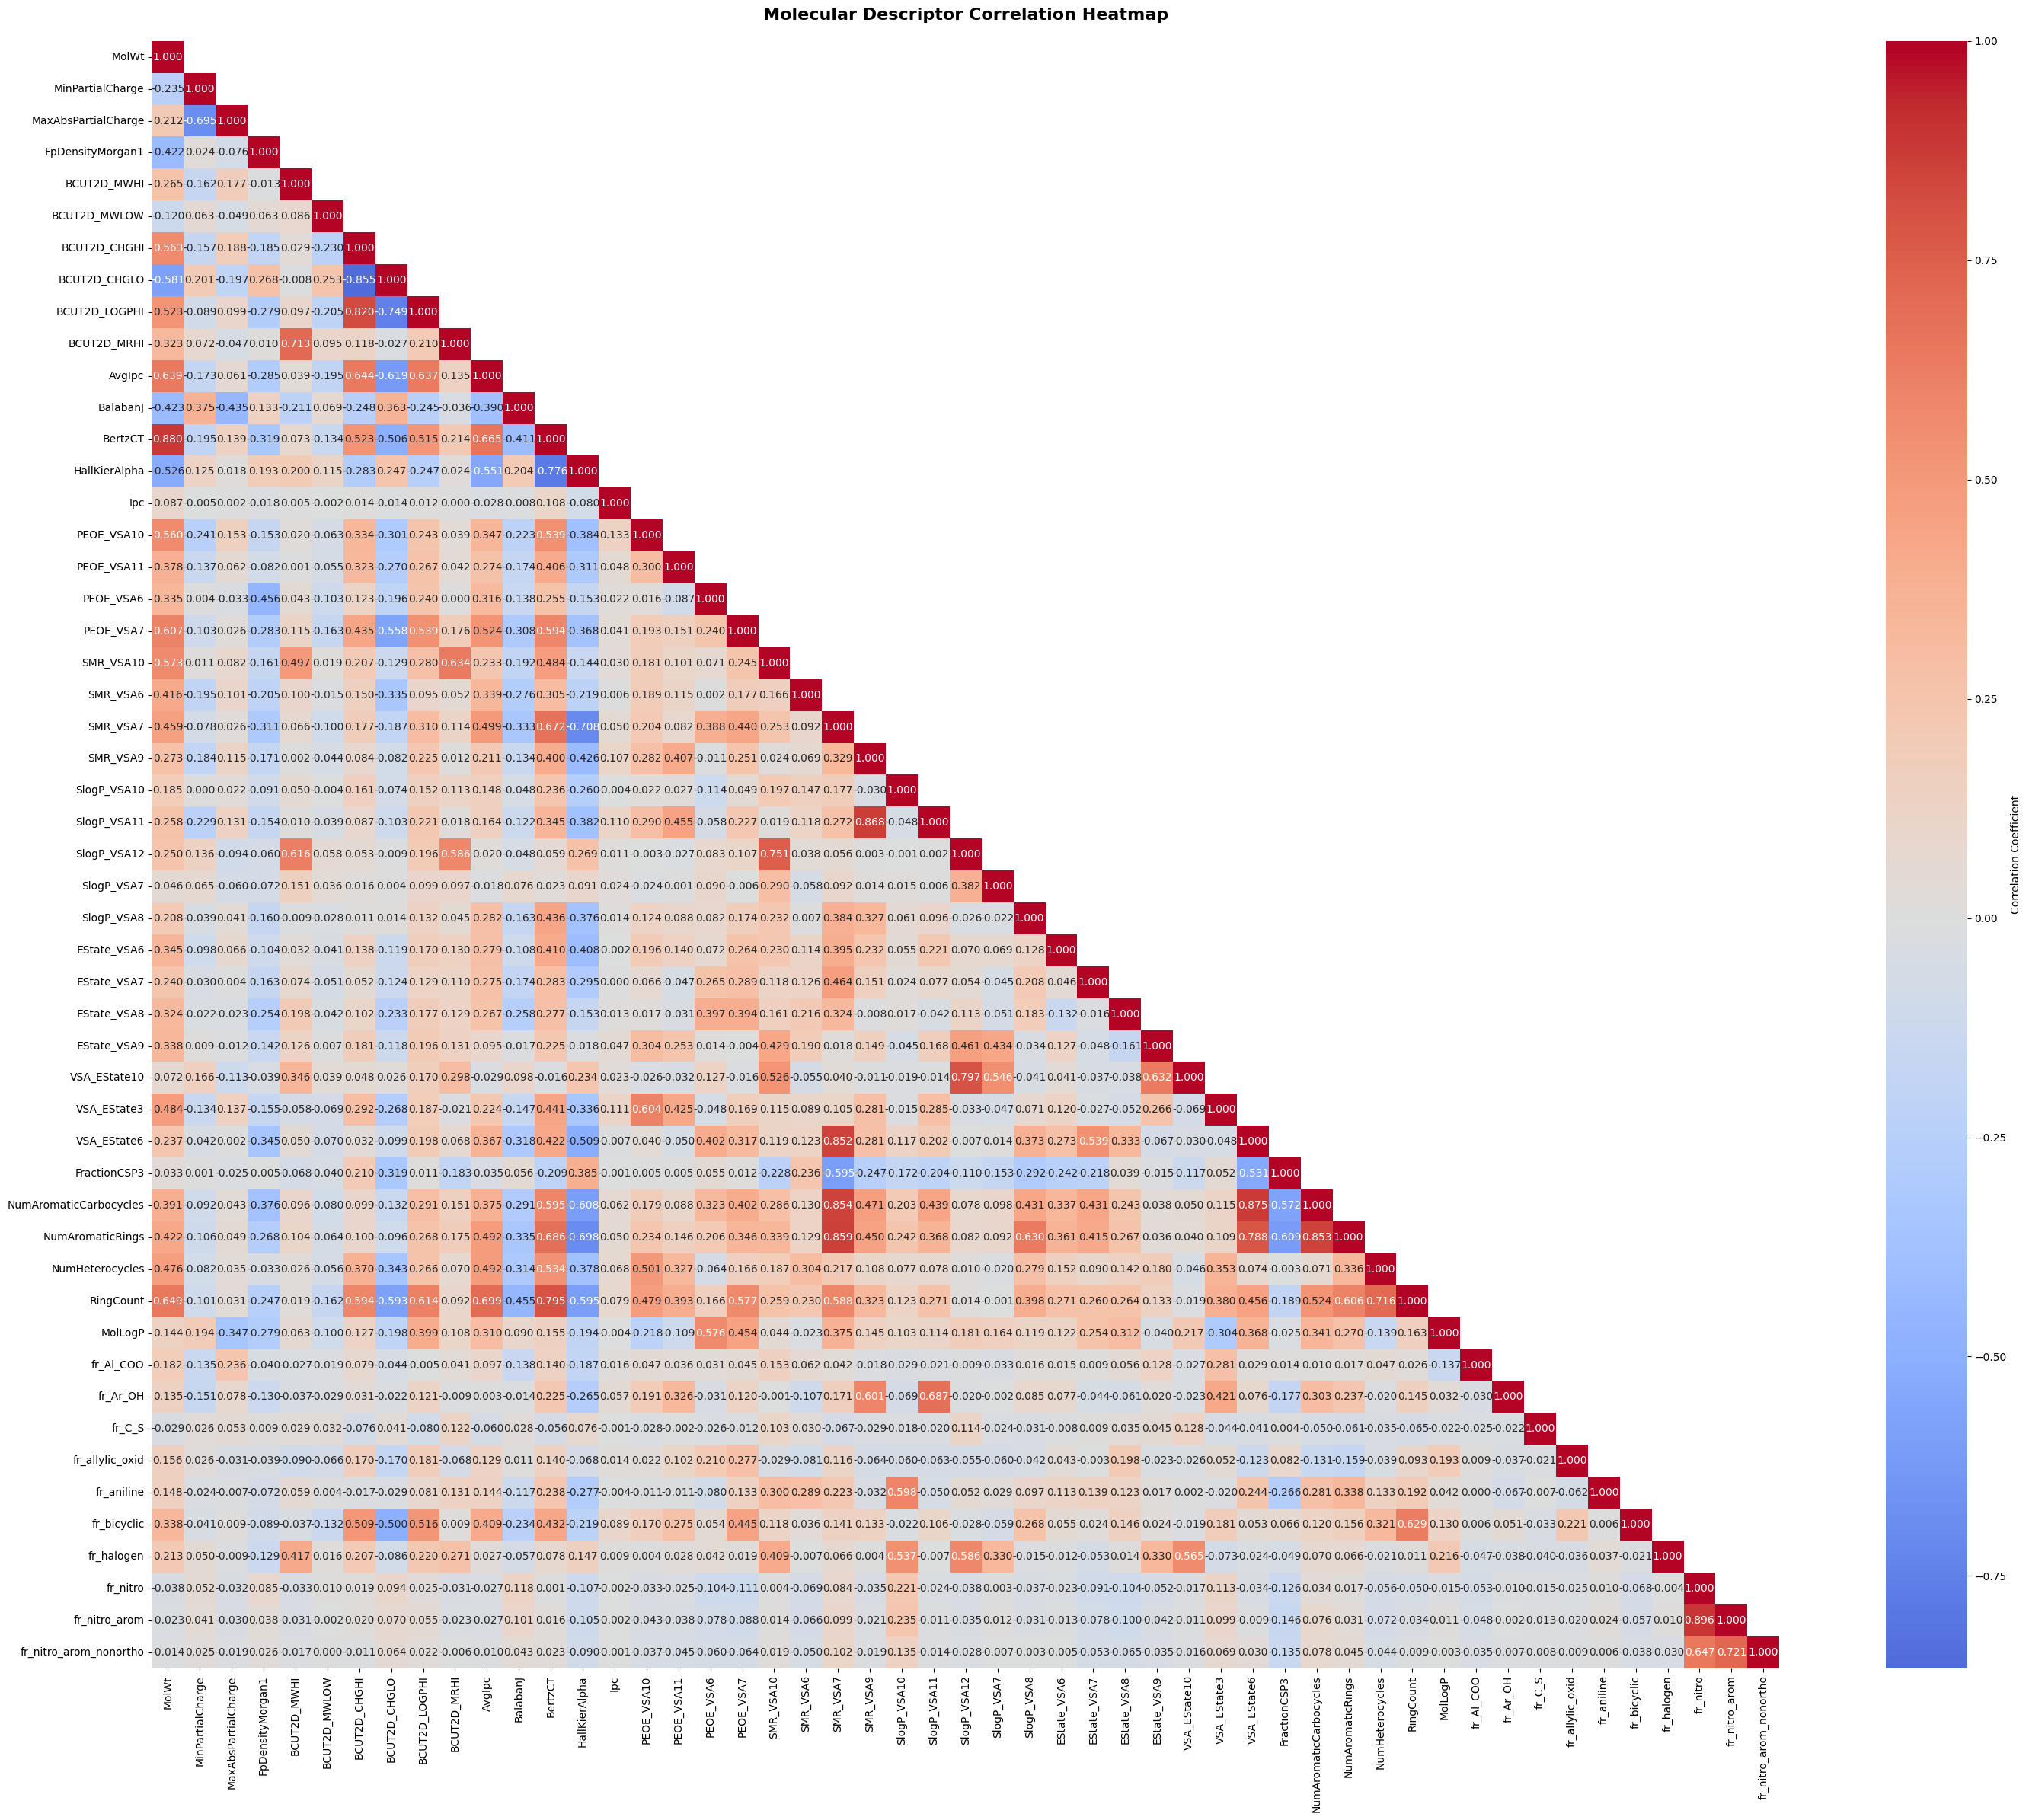

In [37]:
%matplotlib inline
descriptor_data = simplified_df_v5.iloc[:, 9:].select_dtypes(include="number")
correlation_matrix = descriptor_data.corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)

plt.figure(figsize=(30, 24))
sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    center=0,
    square=True,
    fmt=".3f",
    cbar_kws={"label": "Correlation Coefficient"}
)


plt.title('Molecular Descriptor Correlation Heatmap', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()